In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.colors
import networkx as nx

In [7]:
results_df = pd.read_csv('results/metric_score/params/combined/[\'ER\', \'SBM\', \'RG\', \'RPG\']/nodes_10_to_30_stepsize_1/n_graphs_3/results_combined.csv', index_col=0, header=[0,1])


In [8]:
results_df

ER            \
                                                   silh_mean  silh_std   
divcurves_funs_diffs_shortest_path_distance_sco...  0.710600  0.020392   
divcurves_shortest_path_distance_scores_full        0.705978  0.019014   
divcurves_mds_funs_diffs_shortest_path_distance...  0.719294  0.020821   
divcurves_mds_shortest_path_distance_scores_full    0.722462  0.019767   
divcurves_pca_funs_diffs_shortest_path_distance...  0.733524  0.019786   
divcurves_funs_diffs_shortest_path_distance_sco...  0.675176  0.022378   
divcurves_shortest_path_distance_scores_random      0.682611  0.020584   
divcurves_mds_funs_diffs_shortest_path_distance...  0.680170  0.022605   
divcurves_mds_shortest_path_distance_scores_random  0.692503  0.020588   
divcurves_pca_funs_diffs_shortest_path_distance...  0.696331  0.020644   
divcurves_funs_diffs_shortest_path_distance_sco...  0.708850  0.021440   
divcurves_shortest_path_distance_scores_approx_all  0.704787  0.019820   
divcurves_mds_funs_diffs_shortest_path_distance...  0.717097  0.021836   
divcurves_mds_shortest_path_distance_scores_app...  0.722871  0.020300   
divcurves_pca_funs_diffs_shortest_path_distance...  0.730543  0.020641   
divcurves_funs_diffs_diffusion_distance_scores_...  0.537293  0.035988   
divcurves_diffusion_distance_scores_full            0.508127  0.035790   
divcurves_mds_funs_diffs_diffusion_distance_sco...  0.544732  0.036433   
divcurves_mds_diffusion_distance_scores_full        0.522854  0.036550   
divcurves_pca_funs_diffs_diffusion_distance_sco...  0.541510  0.036750   
divcurves_funs_diffs_diffusion_distance_scores_...  0.496838  0.036127   
divcurves_diffusion_distance_scores_random          0.482391  0.035889   
divcurves_mds_funs_diffs_diffusion_distance_sco...  0.503994  0.036254   
divcurves_mds_diffusion_distance_scores_random      0.490038  0.036240   
divcurves_pca_funs_diffs_diffusion_distance_sco...  0.515463  0.036493   
divcurves_funs_diffs_diffusion_distance_scores_...  0.481815  0.036615   
divcurves_diffusion_distance_scores_approx_all      0.467964  0.036202   
divcurves_mds_funs_diffs_diffusion_distance_sco...  0.484405  0.036830   
divcurves_mds_diffusion_distance_scores_approx_all  0.479649  0.036734   
divcurves_pca_funs_diffs_diffusion_distance_sco...  0.505338  0.036911   
divcurves_funs_diffs_resistance_distance_scores...  0.514722  0.034316   
divcurves_resistance_distance_scores_full           0.492205  0.034062   
divcurves_mds_funs_diffs_resistance_distance_sc...  0.519942  0.034700   
divcurves_mds_resistance_distance_scores_full       0.503454  0.034373   
divcurves_pca_funs_diffs_resistance_distance_sc...  0.517952  0.034190   
divcurves_funs_diffs_resistance_distance_scores...  0.507239  0.034200   
divcurves_resistance_distance_scores_random         0.478996  0.034628   
divcurves_mds_funs_diffs_resistance_distance_sc...  0.513613  0.034594   
divcurves_mds_resistance_distance_scores_random     0.501235  0.034878   
divcurves_pca_funs_diffs_resistance_distance_sc...  0.508022  0.033467   
divcurves_funs_diffs_resistance_distance_scores...  0.481859  0.032826   
divcurves_resistance_distance_scores_approx_all     0.394708  0.033515   
divcurves_mds_funs_diffs_resistance_distance_sc...  0.490446  0.033913   
divcurves_mds_resistance_distance_scores_approx...  0.432385  0.034694   
divcurves_pca_funs_diffs_resistance_distance_sc...  0.490102  0.035033   

                                                                   \
                                                   ari_agglo_mean   
divcurves_funs_diffs_shortest_path_distance_sco...       0.486951   
divcurves_shortest_path_distance_scores_full             0.485482   
divcurves_mds_funs_diffs_shortest_path_distance...       0.488270   
divcurves_mds_shortest_path_distance_scores_full         0.487896   
divcurves_pca_funs_diffs_shortest_path_distance...       0.485103   
divcurves_funs_diffs_shortest_path_distance_sco...       0.470352   
divcurves_shortest_path_dis

In [9]:
configs_df

NameError: name 'configs_df' is not defined

In [6]:
resdir = 'mag_graph/simulations/results/simulations/clustering/ablations/combined/[\'ER\', \'SBM\', \'RG\', \'RPG\']/nodes_10_to_30_stepsize_1/n_graphs_3/'

# tables per model seperate
results_df = pd.read_csv(f'{resdir}results_combined.csv', header=[0,1], index_col=0)
configs_df = pd.read_csv(f'{resdir}configs.csv', header=0, index_col=0)

scores = ['acc', 'silh', 'db', 'ch', 'ari_agglo', 'ari_kmeans']
scores_asc = {'acc': False, 'silh': False, 'ari_agglo': False, 'db': True,'ch': False, 'ari_kmeans': False}

#only use selected rows
scores_methods = ['full', 'random', 'approx_all']
graph_metrics = ['shortest_path_distance', "diffusion_distance", "resistance_distance"]
# metric = ['acc', 'silh', 'ari_agglo', 'db',	'ch', 'ari_kmeans'][1]
div_curve_method = 'divcurves_'
selected_rows = [div_curve_method+graph_metric+'_scores_' + scores_method for graph_metric in graph_metrics for scores_method in scores_methods]

results_df = results_df.loc[selected_rows, :]

res_copy = results_df.copy()


# results_latex = pd.DataFrame(index=res_copy.index)
results_latex_dfs = {}
models = list(np.unique(res_copy.columns.get_level_values(0)))

for model in models:
    results_latex_model = {}
    for score in scores:
        mean_col = (model, f'{score}_mean')
        std_col = (model, f'{score}_std')

        if mean_col in res_copy.columns and std_col in res_copy.columns:
            results_latex_model[score] = res_copy[mean_col].combine(
                res_copy[std_col],
                lambda m, s: f"{m:.3f} $\\pm $ {s:.3f}"
            )
    results_latex_df_model = pd.DataFrame.from_dict(results_latex_model)
    

# Bold the best mean for each score within each top-level group

    for score in scores:
        mean_col = (model, f"{score}_mean")
        display_col = (model, score)
        if mean_col in res_copy.columns:
            if not scores_asc[score]: 
                best_mask = res_copy[mean_col] == res_copy[mean_col].max()
            else:
                best_mask = res_copy[mean_col] == res_copy[mean_col].min()
            results_latex_df_model.loc[best_mask, score] = results_latex_df_model.loc[best_mask, score].apply(
                lambda x: f"\\textbf{{{x}}}"
            )
        else:
            print(f'{mean_col} not in dataframe?')

    # finejustierung tabelle
    new_index = {
        'divcurves_shortest_path_distance_scores_full': ('shortest path', 'spread'),
        'divcurves_shortest_path_distance_scores_random': ('shortest path', 'random'),
        'divcurves_shortest_path_distance_scores_approx_all': ('shortest path', 'approx.'),
        'divcurves_diffusion_distance_scores_full': ('diffusion', 'spread'),
        'divcurves_diffusion_distance_scores_random': ('diffusion', 'random'),
        'divcurves_diffusion_distance_scores_approx_all': ('diffusion', 'approx.'),
        'divcurves_resistance_distance_scores_full': ('resistance',' spread'),
        'divcurves_resistance_distance_scores_random': ('resistance',' random'),
        'divcurves_resistance_distance_scores_approx_all': ('resistance',' approx.'),
    }
    results_latex_df_model = results_latex_df_model.rename(new_index)
    results_latex_df_model.index = pd.MultiIndex.from_tuples(results_latex_df_model.index)
    results_latex_df_model.index.rename(['Distance', 'Score'], inplace=True)
    new_cols = {
        'acc': 'Accuracy', 
        'silh': 'Silhouette Score', 
        'db': 'Davies-Bouldin', 
        'ch': 'Calinski-Harabasz', 
        'ari_kmeans': 'ARI k-means', 
        'ari_agglo': 'ARI agglomerative'
    }

    results_latex_df_model = results_latex_df_model.rename(columns=new_cols)

    results_latex_dfs[model] = results_latex_df_model


for model in models:
    print(f'model: {model} with config {configs_df.loc[(model, 'configurations')]}')
    print(results_latex_dfs[model].to_latex(multirow=False))

SyntaxError: f-string: unmatched '(' (4117920129.py, line 86)

In [6]:
pd.MultiIndex.from_tuples(results_latex_df_model.index)

MultiIndex([('shortest path',   'spread'),
            ('shortest path',   'random'),
            ('shortest path',  'approx.'),
            (    'diffusion',   'spread'),
            (    'diffusion',   'random'),
            (    'diffusion',  'approx.'),
            (   'resistance',  ' spread'),
            (   'resistance',  ' random'),
            (   'resistance', ' approx.')],
           )

In [7]:
results_latex_df_model

Accuracy  \
Distance      Score                                   
shortest path spread    \textbf{0.861 $\pm $ 0.062}   
              random             0.856 $\pm $ 0.079   
              approx.            0.861 $\pm $ 0.062   
diffusion     spread             0.783 $\pm $ 0.072   
              random             0.822 $\pm $ 0.054   
              approx.            0.783 $\pm $ 0.072   
resistance     spread            0.822 $\pm $ 0.060   
               random            0.817 $\pm $ 0.061   
               approx.           0.817 $\pm $ 0.050   

                                   Silhouette Score  \
Distance      Score                                   
shortest path spread    \textbf{0.301 $\pm $ 0.034}   
              random             0.288 $\pm $ 0.036   
              approx.            0.273 $\pm $ 0.034   
diffusion     spread             0.050 $\pm $ 0.033   
              random             0.048 $\pm $ 0.034   
              approx.            0.050 $\pm $ 0.033   
resistance     spread            0.230 $\pm $ 0.033   
               random            0.267 $\pm $ 0.038   
               approx.           0.223 $\pm $ 0.034   

                                     Davies-Bouldin  \
Distance      Score                                   
shortest path spread             1.122 $\pm $ 0.130   
              random             1.062 $\pm $ 0.115   
              approx.            1.154 $\pm $ 0.130   
diffusion     spread             2.158 $\pm $ 0.446   
              random             2.156 $\pm $ 0.457   
              approx.            2.161 $\pm $ 0.444   
resistance     spread            1.213 $\pm $ 0.128   
               random   \textbf{1.059 $\pm $ 0.106}   
               approx.           1.237 $\pm $ 0.128   

                                    Calinski-Harabasz  \
Distance      Score                                     
shortest path spread             94.305 $\pm $ 13.963   
              random    \textbf{98.923 $\pm $ 15.813}   
              approx.            87.747 $\pm $ 13.267   
diffusion     spread              25.955 $\pm $ 5.913   
              random              25.918 $\pm $ 6.075   
              approx.             25.843 $\pm $ 5.908   
resistance     spread            70.056 $\pm $ 10.781   
               random            87.486 $\pm $ 15.035   
               approx.           66.452 $\pm $ 10.478   

                                  ARI agglomerative  \
Distance      Score                                   
shortest path spread             0.371 $\pm $ 0.117   
              random    \textbf{0.397 $\pm $ 0.064}   
              approx.            0.376 $\pm $ 0.108   
diffusion     spread             0.153 $\pm $ 0.058   
              random             0.162 $\pm $ 0.047   
              approx.            0.152 $\pm $ 0.056   
resistance     spread            0.329 $\pm $ 0.095   
               random            0.361 $\pm $ 0.084   
               approx.           0.328 $\pm $ 0.094   

                                        ARI k-means  
Distance      Score                                  
shortest path spread    \textbf{0.432 $\pm $ 0.076}  
              random             0.427 $\pm $ 0.068  
              approx.            0.421 $\pm $ 0.074  
diffusion     spread             0.136 $\pm $ 0.035  
              random             0.160 $\pm $ 0.045  
              approx.            0.136 $\pm $ 0.035  
resistance     spread            0.374 $\pm $ 0.067  
               random            0.399 $\pm $ 0.078  
               approx.           0.364 $\pm $ 0.069

In [11]:
new_index = {
    'divcurves_shortest_path_distance_scores_full': ('shortest path', 'spread'),
    'divcurves_shortest_path_distance_scores_random': ('shortest path', 'random'),
    'divcurves_shortest_path_distance_scores_approx_all': ('shortest path', 'approx.'),
    'divcurves_diffusion_distance_scores_full': ('diffusion', 'spread'),
    'divcurves_diffusion_distance_scores_random': ('diffusion', 'random'),
    'divcurves_diffusion_distance_scores_approx_all': ('diffusion', 'approx.'),
    'divcurves_resistance_distance_scores_full': ('resistance',' spread'),
    'divcurves_resistance_distance_scores_random': ('resistance',' random'),
    'divcurves_resistance_distance_scores_approx_all': ('resistance',' approx.'),
}

In [12]:
new_names = {
    'divcurves_shortest_path_distance_scores_full': 'shortest path, spread',
    'divcurves_shortest_path_distance_scores_random': 'shortest path, random',
    'divcurves_shortest_path_distance_scores_approx_all': 'shortest path, approx.',
    'divcurves_diffusion_distance_scores_full': 'diffusion, spread',
    'divcurves_diffusion_distance_scores_random': 'diffusion, random',
    'divcurves_diffusion_distance_scores_approx_all': 'diffusion, approx.',
    'divcurves_resistance_distance_scores_full': 'resistance, spread',
    'divcurves_resistance_distance_scores_random': 'resistance, random',
    'divcurves_resistance_distance_scores_approx_all': 'resistance, approx.',
}

In [13]:
def categorical_cmap(nc, nsc, cmap="tab10", continuous=False):
    if nc > plt.get_cmap(cmap).N:
        raise ValueError("Too many categories for colormap.")
    if continuous:
        ccolors = plt.get_cmap(cmap)(np.linspace(0,1,nc))
    else:
        ccolors = plt.get_cmap(cmap)(np.arange(nc, dtype=int))
    cols = np.zeros((nc*nsc, 3))
    for i, c in enumerate(ccolors):
        chsv = matplotlib.colors.rgb_to_hsv(c[:3])
        arhsv = np.tile(chsv,nsc).reshape(nsc,3)
        arhsv[:,1] = np.linspace(chsv[1],0.25,nsc)
        arhsv[:,2] = np.linspace(chsv[2],1,nsc)
        rgb = matplotlib.colors.hsv_to_rgb(arhsv)
        cols[i*nsc:(i+1)*nsc,:] = rgb       
    cmap = matplotlib.colors.ListedColormap(cols)
    return cmap


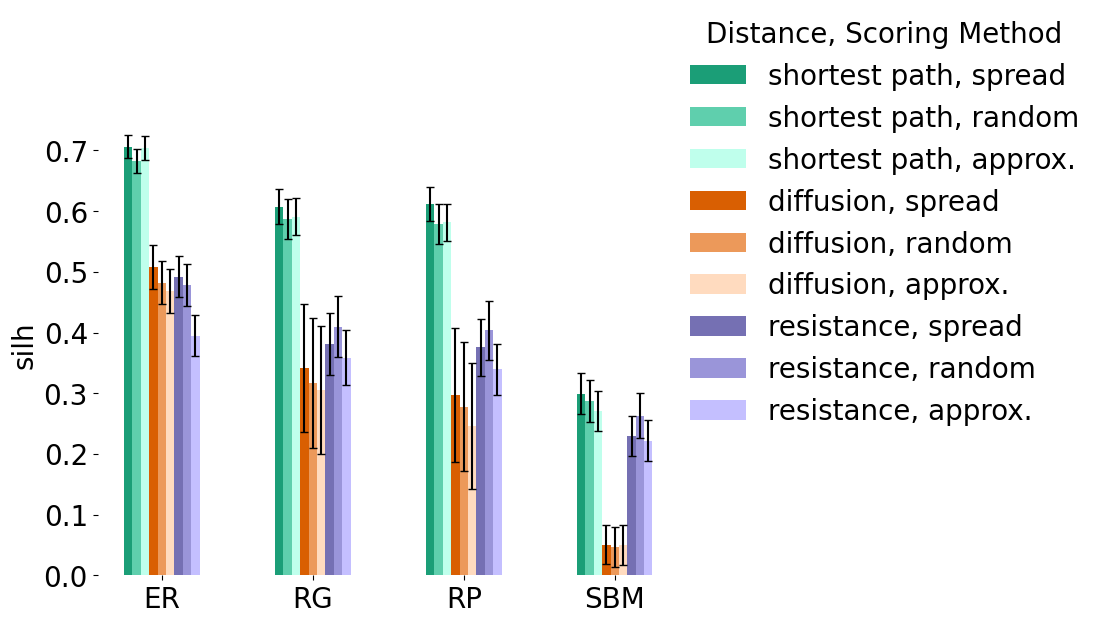

In [ ]:
models = list(np.unique(results_df.columns.get_level_values(0)))

scores_methods = ['full', 'random', 'approx_all']
graph_metrics = ['shortest_path_distance', "diffusion_distance", "resistance_distance"]
metric = ['acc', 'silh', 'ari_agglo', 'db',	'ch', 'ari_kmeans'][1]
div_curve_method = 'divcurves_'

selected_rows = [div_curve_method+graph_metric+'_scores_' + scores_method for graph_metric in graph_metrics for scores_method in scores_methods]

select_df = results_df.loc[selected_rows, (models, [metric+'_mean', metric+'_std'])]
y=select_df.loc[:, (slice(None), [f'{metric}_mean'])].droplevel(level=1, axis=1)
y_err = select_df.loc[:, (slice(None), [f'{metric}_std'])].droplevel(level=1, axis=1)


matplotlib.rcParams.update({'font.size': 20})
# Assuming y and y_err are DataFrames with columns ['ER', 'BA', 'SBM']
# and multiple rows

fig, ax = plt.subplots(figsize=(10, 6))

# Get the models (column names)
models = y.columns  # ['ER', 'BA', 'SBM']
n_rows = len(y)
x_positions = np.arange(len(models))

# Width for offsetting errorbars within each model group
bar_width = 0.5 / n_rows  # Adjust divisor to control spacing

# Colors for each row
cmap = categorical_cmap(4,3,cmap='Dark2')
colors = cmap(X=range(n_rows))
# colors = plt.cm.tab10(X=range(n_rows))

bars = {}

# Plot errorbars for each row
for row_idx, row_name in enumerate(y.index):
    offsets = x_positions + (row_idx - n_rows/2 + 0.5) * bar_width
    ax.errorbar(
        offsets, 
        y.iloc[row_idx],
        yerr=y_err.iloc[row_idx],
        fmt='none',
        label=row_name,
        color='black',
        capsize=3,
        markersize=6
    )
    bars[row_name] = ax.bar(offsets, y.iloc[row_idx], width=bar_width, color=colors[row_idx])

ax = plt.gca()
ax.set_xticks(x_positions)
ax.set_xticklabels([model if model != 'RPG' else 'RP' for model in models])
# ax.set_xlabel('Model')
ax.set_ylabel(metric)
# ax.set_ylim( top=1) #bottom=-1,
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(False)

box = ax.get_position()
ax.set_position([box.x0, box.y0, box.width * 0.75, box.height])

ax.legend(handles = [bars[row] for row in y.index],
           labels=[new_names[row] for row in y.index],
           frameon=False,
           loc=(1.04, 0), bbox_to_anchor=(1, 0.3),
           title='Distance, Scoring Method', 
           )

# ax.grid(axis='y', alpha=0.3)
# ax.grid(axis='x', visible=False)
# plt.tight_layout()

# plt.show()

# plt.savefig(f'output/ablation_{metric}.pdf', dpi=300, format='pdf', bbox_inches="tight")

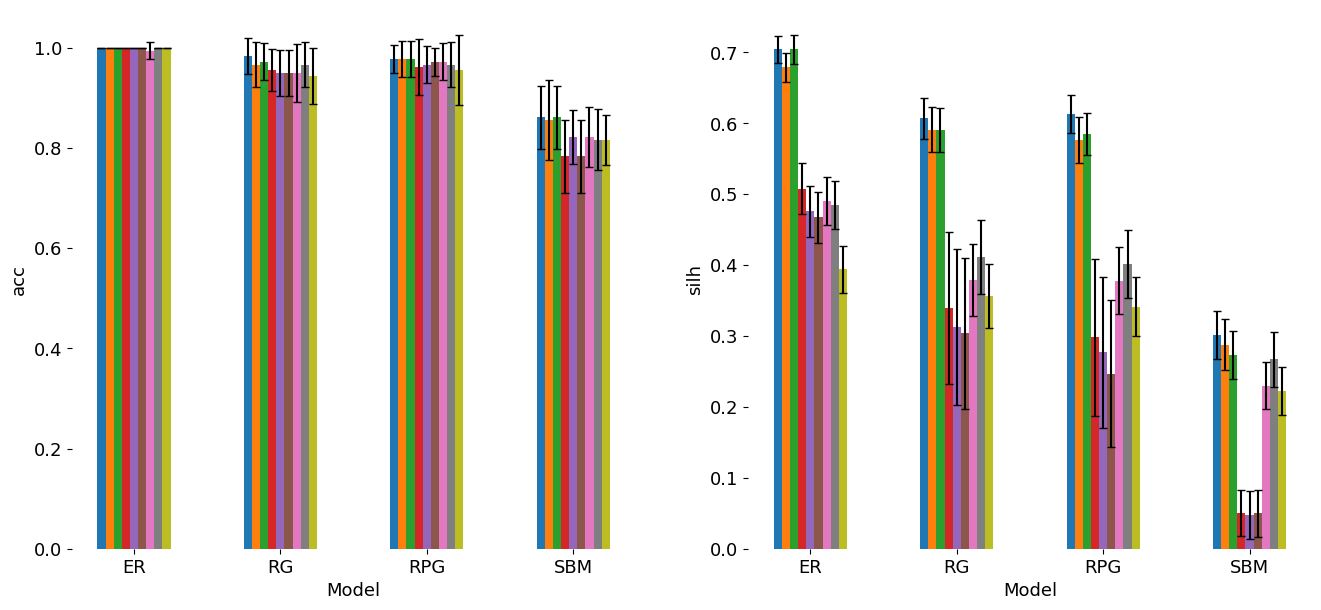

In [8]:
matplotlib.rcParams.update({'font.size': 13})


outerfig, outeraxs = plt.subplots(1, 2, figsize=(8 * (2), 7 * (1)))

for i, metric in enumerate(['acc', 'silh']):
    selected = [div_curve_method+graph_metric+'_scores_' + scores_method for graph_metric in graph_metrics for scores_method in scores_methods]

    select_df = results_df.loc[selected, (models, [metric+'_mean', metric+'_std'])]
    y=select_df.loc[:, (slice(None), [f'{metric}_mean'])].droplevel(level=1, axis=1)
    y_err = select_df.loc[:, (slice(None), [f'{metric}_std'])].droplevel(level=1, axis=1)


    # Assuming y and y_err are DataFrames with columns ['ER', 'BA', 'SBM']
    # and multiple rows

    # fig, ax = plt.subplots(figsize=(10, 6))

    # Get the models (column names)
    models = y.columns  # ['ER', 'BA', 'SBM']
    n_rows = len(y)
    x_positions = np.arange(len(models))

    # Width for offsetting errorbars within each model group
    bar_width = 0.5 / n_rows  # Adjust divisor to control spacing

    # Colors for each row
    # colors = plt.cm.Dark2(X=range(n_rows))
    colors = plt.cm.tab10(X=range(n_rows))

    bars = {}

    # Plot errorbars for each row
    for row_idx, row_name in enumerate(y.index):
        offsets = x_positions + (row_idx - n_rows/2 + 0.5) * bar_width
        outeraxs[i].errorbar(
            offsets, 
            y.iloc[row_idx],
            yerr=y_err.iloc[row_idx],
            fmt='none',
            label=row_name,
            color='black',
            capsize=3,
            markersize=6
        )
        bars[row_name] = outeraxs[i].bar(offsets, y.iloc[row_idx], width=bar_width, color=colors[row_idx])

    # ax = plt.gca()
    outeraxs[i].set_xticks(x_positions)
    outeraxs[i].set_xticklabels(models)
    outeraxs[i].set_xlabel('Model')
    outeraxs[i].set_ylabel(metric)
    # ax.set_ylim( top=1) #bottom=-1,
    outeraxs[i].spines['top'].set_visible(False)
    outeraxs[i].spines['right'].set_visible(False)
    outeraxs[i].spines['bottom'].set_visible(False)
    outeraxs[i].spines['left'].set_visible(False)
    outeraxs[i].grid(False)
# ax.legend(handles = [bars[row] for row in y.index],
#         labels=[row for row in y.index],
#         frameon=False)


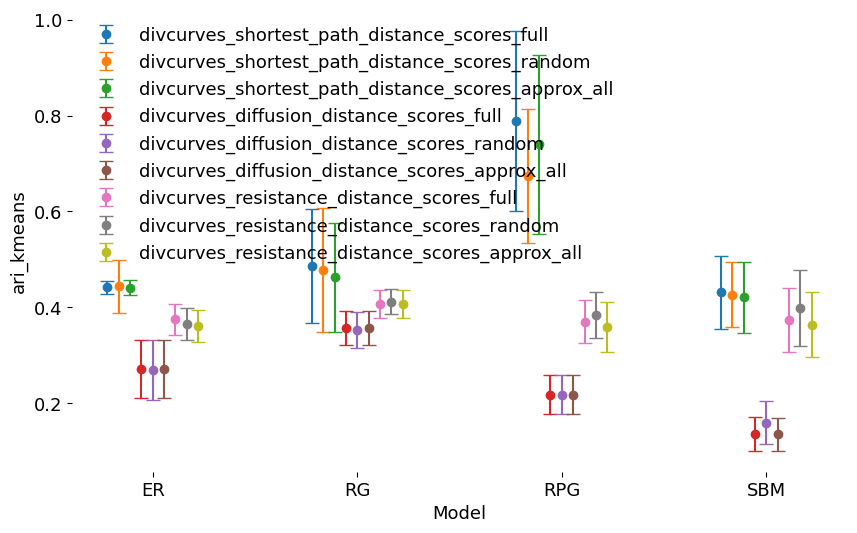

In [9]:
models = list(np.unique(results_df.columns.get_level_values(0)))

scores_methods = ['full', 'random', 'approx_all']
graph_metrics = ['shortest_path_distance', "diffusion_distance", "resistance_distance"]
metric = ['acc', 'silh', 'ari_agglo', 'db',	'ch', 'ari_kmeans'][5]
div_curve_method = 'divcurves_'

selected = [div_curve_method+graph_metric+'_scores_' + scores_method for graph_metric in graph_metrics for scores_method in scores_methods]

select_df = results_df.loc[selected, (models, [metric+'_mean', metric+'_std'])]
y=select_df.loc[:, (slice(None), [f'{metric}_mean'])].droplevel(level=1, axis=1)
y_err = select_df.loc[:, (slice(None), [f'{metric}_std'])].droplevel(level=1, axis=1)


matplotlib.rcParams.update({'font.size': 13})
# Assuming y and y_err are DataFrames with columns ['ER', 'BA', 'SBM']
# and multiple rows

fig, ax = plt.subplots(figsize=(10, 6))

# Get the models (column names)
models = y.columns  # ['ER', 'BA', 'SBM']
n_rows = len(y)
x_positions = np.arange(len(models))

# Width for offsetting errorbars within each model group
bar_width = 0.5 / n_rows  # Adjust divisor to control spacing

# Colors for each row
# colors = plt.cm.Dark2(X=range(n_rows))
colors = plt.cm.tab10(X=range(n_rows))

bars = {}
errb = {}

# Plot errorbars for each row
for row_idx, row_name in enumerate(y.index):
    offsets = x_positions + (row_idx - n_rows/2 + 0.5) * bar_width
    errb[row_name] = ax.errorbar(
        offsets, 
        y.iloc[row_idx],
        yerr=y_err.iloc[row_idx],
        fmt='o',
        label=row_name,
        color=colors[row_idx],
        capsize=5,
        markersize=6
    )
    # bars[row_name] = ax.bar(offsets, y.iloc[row_idx], width=bar_width, color=colors[row_idx])

ax = plt.gca()
ax.set_xticks(x_positions)
ax.set_xticklabels(models)
ax.set_xlabel('Model')
ax.set_ylabel(metric)
# ax.set_ylim( top=1) #bottom=-1,
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(False)
ax.legend(handles = [errb[row] for row in y.index],
           labels=[row for row in y.index],
           frameon=False)

# ax.grid(axis='y', alpha=0.3)
# ax.grid(axis='x', visible=False)
# plt.tight_layout()

plt.show()

# plt.savefig(f'output/{score}.pdf', dpi=300, format='pdf')

In [48]:
y=select_df.loc[:, (slice(None), [f'{metric}_mean'])].droplevel(level=1, axis=1)
y_err = select_df.loc[:, (slice(None), [f'{metric}_std'])].droplevel(level=1, axis=1)


matplotlib.rcParams.update({'font.size': 13})
# Assuming y and y_err are DataFrames with columns ['ER', 'BA', 'SBM']
# and multiple rows

fig, ax = plt.subplots(figsize=(10, 6))

# Get the models (column names)
models = y.columns  # ['ER', 'BA', 'SBM']
n_rows = len(y)
x_positions = np.arange(len(models))

# Width for offsetting errorbars within each model group
bar_width = 0.5 / n_rows  # Adjust divisor to control spacing

# Colors for each row
# colors = plt.cm.Dark2(X=range(n_rows))
colors = plt.cm.tab10(X=range(n_rows))

bars = {}

# Plot errorbars for each row
for row_idx, row_name in enumerate(y.index):
    offsets = x_positions + (row_idx - n_rows/2 + 0.5) * bar_width
    ax.errorbar(
        offsets, 
        y.iloc[row_idx],
        yerr=y_err.iloc[row_idx],
        fmt='none',
        label=row_name,
        color='black',
        capsize=3,
        markersize=6
    )
    bars[row_name] = ax.bar(offsets, y.iloc[row_idx], width=bar_width, color=colors[row_idx])

ax = plt.gca()
ax.set_xticks(x_positions)
ax.set_xticklabels(models)
ax.set_xlabel('Model')
ax.set_ylabel(metric)
# ax.set_ylim( top=1) #bottom=-1,
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.grid(False)
ax.legend(handles = [bars[row] for row in y.index],
           labels=[row for row in y.index],
           frameon=False)

# ax.grid(axis='y', alpha=0.3)
# ax.grid(axis='x', visible=False)
# plt.tight_layout()

plt.show()

# plt.savefig(f'output/{score}.pdf', dpi=300, format='pdf')

NameError: name 'select_df' is not defined

AttributeError: Line2D.set() got an unexpected keyword argument 'hue'

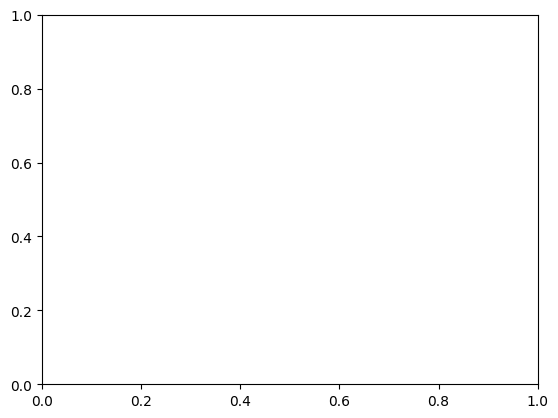

In [28]:
select_df.plot(hue='index')